# PRACTICA 3

## Ejercicio 1: Principal Components Analysis (PCA)

In [24]:
%matplotlib inline


import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn import datasets
import numpy as np

from sklearn.decomposition import PCA
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

#Cargamos el dataset
iris = datasets.load_iris()

In [5]:
features = iris.data
label = iris.target
print (features.shape)

(150, 4)


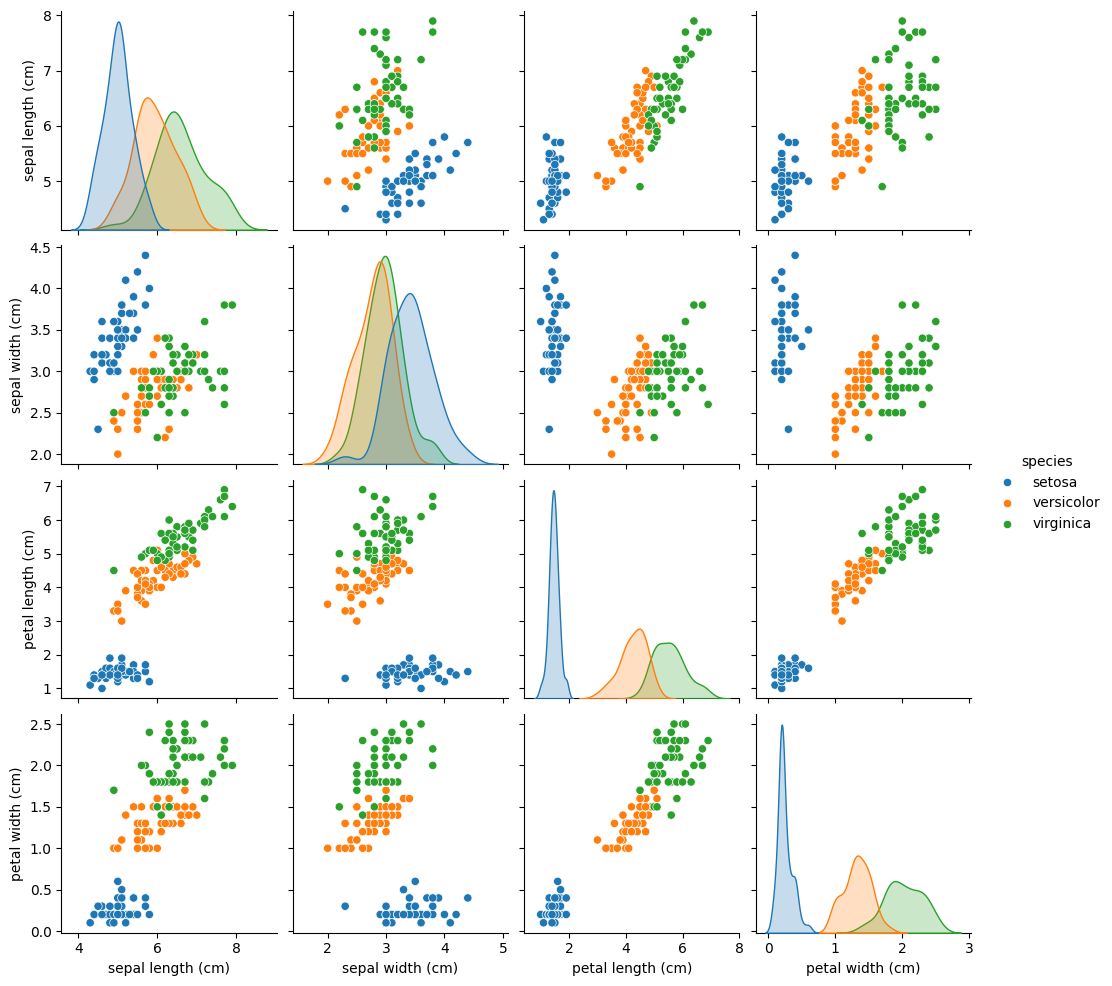

In [33]:
# Crear DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = iris.target

# Convertir target a nombres de especies
df["species"] = df["species"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})

# Visualización de variables dos a dos
sns.pairplot(df, hue="species")
plt.show()

Al observar los gráficos de dispersión entre pares de variables se aprecia que la especie setosa se separa claramente de las otras dos especies. Por otro lado, versicolor y virginica presentan cierto solapamiento en algunas combinaciones de variables. Las variables relacionadas con el pétalo parecen ser las que mejor diferencian las especies.

In [34]:
df.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [35]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [44]:
# Separamos las variables
features = df.drop("species", axis=1)
target = df["species"]

# Estandarizamos las variables
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

In [45]:
# Creamos objeto PCA con 3 componentes
pca3 = PCA(n_components=3)
pca3.fit(features_scaled)
features_reduced_3 = pca3.transform(features_scaled)

print(features_reduced_3.shape)

(150, 3)


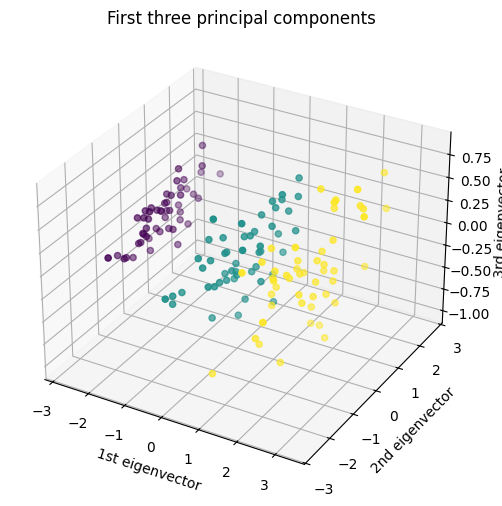

In [46]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(features_reduced_3[:,0],
           features_reduced_3[:,1],
           features_reduced_3[:,2],
           c=label)

ax.set_title("First three principal components")
ax.set_xlabel("1st eigenvector")
ax.set_ylabel("2nd eigenvector")
ax.set_zlabel("3rd eigenvector")

plt.show()

In [47]:
# Crear PCA con 2 componentes
pca2 = PCA(n_components=2)

# Ajustar el modelo
pca2.fit(features_scaled)

# Transformar los datos
features_reduced_2 = pca2.transform(features_scaled)

print(features_reduced_2.shape)

(150, 2)


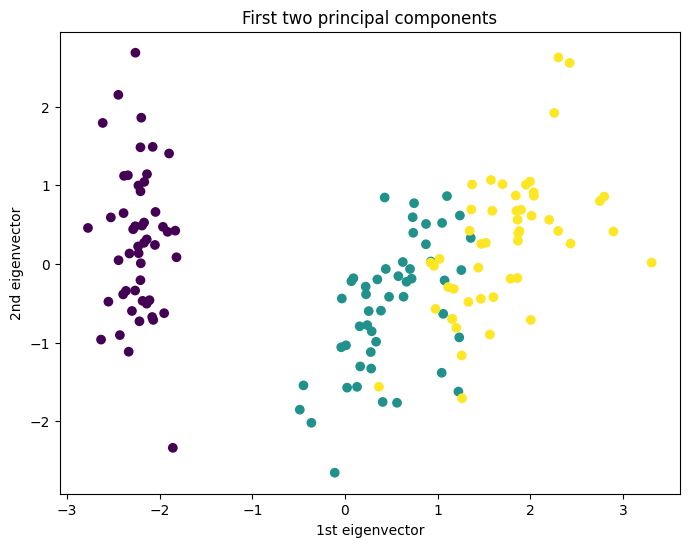

In [43]:
#hacemos el grafico en 2D

plt.figure(figsize=(8,6))

plt.scatter(features_reduced_2[:,0],
            features_reduced_2[:,1],
            c=label)

plt.title("First two principal components")
plt.xlabel("1st eigenvector")
plt.ylabel("2nd eigenvector")

plt.show()

In [55]:
# PCA con todos los componentes
pca = PCA(n_components=4)

# Ajustamos el modelo
pca.fit(features_scaled)

# Porcentaje de varianza explicada por cada componente
print(pca.explained_variance_ratio_)

[0.72962445 0.22850762 0.03668922 0.00517871]


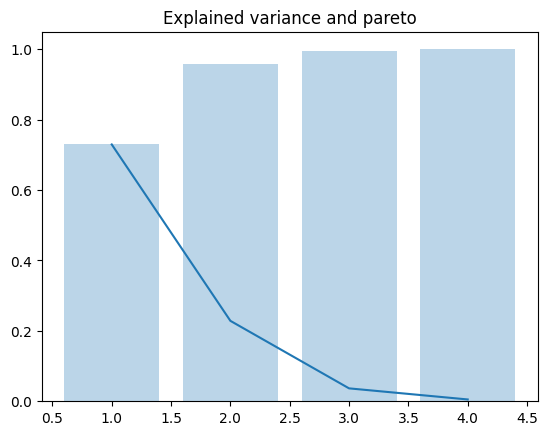

In [56]:
plt.plot(range(1,5),pca.explained_variance_ratio_)
plt.bar(range(1,5),np.cumsum(pca.explained_variance_ratio_), alpha=.3)
plt.title("Explained variance and pareto")
plt.show()

Dos componentes serán suficientes ya que suman el 95% de los datos.

## t-Distributed Stochastic Neighbor Embedding (t-SNE)

In [57]:
from sklearn.datasets import load_digits

# Cargar el conjunto de datos MNIST-like
digits = load_digits()

# Acceder a los datos y las etiquetas
X = digits.data  # Datos de las imágenes
y = digits.target  # Etiquetas (dígitos)

print(X.shape, y.shape)

(1797, 64) (1797,)


In [58]:
feat_cols = [ 'pixel'+str(i) for i in range(X.shape[1]) ]

df = pd.DataFrame(X,columns=feat_cols)
df['y'] = y
df['label'] = df['y'].apply(lambda i: str(i))

X, y = None, None

print('Size of the dataframe: {}'.format(df.shape))
df.head()

Size of the dataframe: (1797, 66)


,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel56,pixel57,pixel58,pixel59,pixel60,pixel61,pixel62,pixel63,y,label
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4,4


### PCA

In [59]:
# Separar variables predictoras
features = df[feat_cols]

# Estandarizar
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

In [61]:
# PCA con 2 componentes
pca = PCA(n_components=2)

# Ajustar y transformar
pca_result = pca.fit_transform(features_scaled)

print(pca_result.shape)

(1797, 2)


In [65]:
# Guardar componentes en el dataframe
df['PCA1'] = pca_result[:, 0]
df['PCA2'] = pca_result[:, 1]

print('Varianza explicada por cada componente:', pca.explained_variance_ratio_)
print('Varianza acumulada:', np.cumsum(pca.explained_variance_ratio_))

Varianza explicada por cada componente: [0.12033916 0.09561054]
Varianza acumulada: [0.12033916 0.21594971]


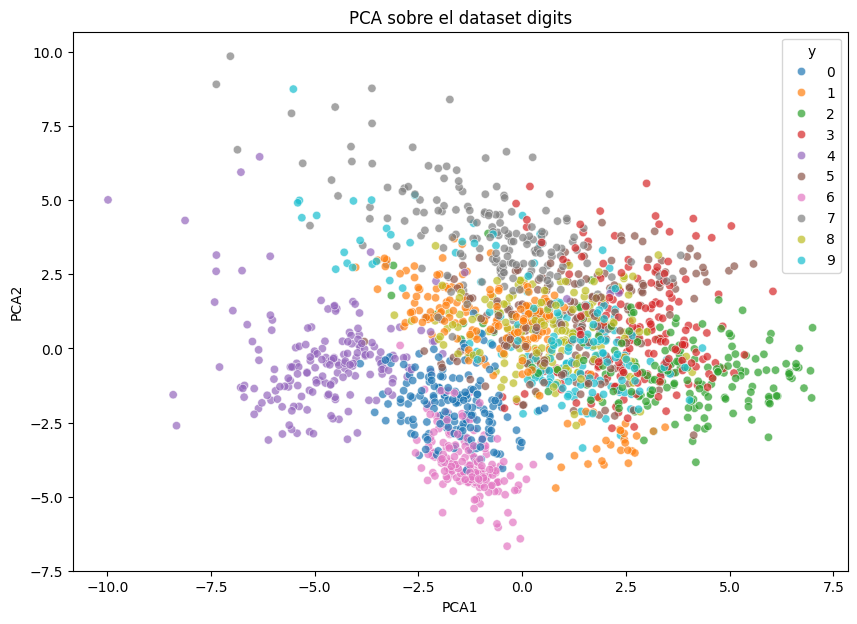

In [66]:
#Gráfico
plt.figure(figsize=(10,7))
sns.scatterplot(
    x='PCA1',
    y='PCA2',
    hue='y',
    palette='tab10',
    data=df,
    alpha=0.7
)

plt.title('PCA sobre el dataset digits')
plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.show()

En el gráfico se observan ciertas agrupaciones de los distintos dígitos, lo que indica que las dos primeras componentes principales capturan parte de la estructura del dataset. Sin embargo, también aparece solapamiento entre algunas clases, por lo que no todos los números quedan claramente separados. Al ser un método lineal, puede no separar completamente clases complejas como los dígitos manuscritos.

### t-SNE

In [67]:
from sklearn.manifold import TSNE

# Aplicar t-SNE
tsne = TSNE(n_components=2, random_state=0)

tsne_result = tsne.fit_transform(features_scaled)

# Guardar resultados en el dataframe
df['TSNE1'] = tsne_result[:,0]
df['TSNE2'] = tsne_result[:,1]

print(tsne_result.shape)

(1797, 2)


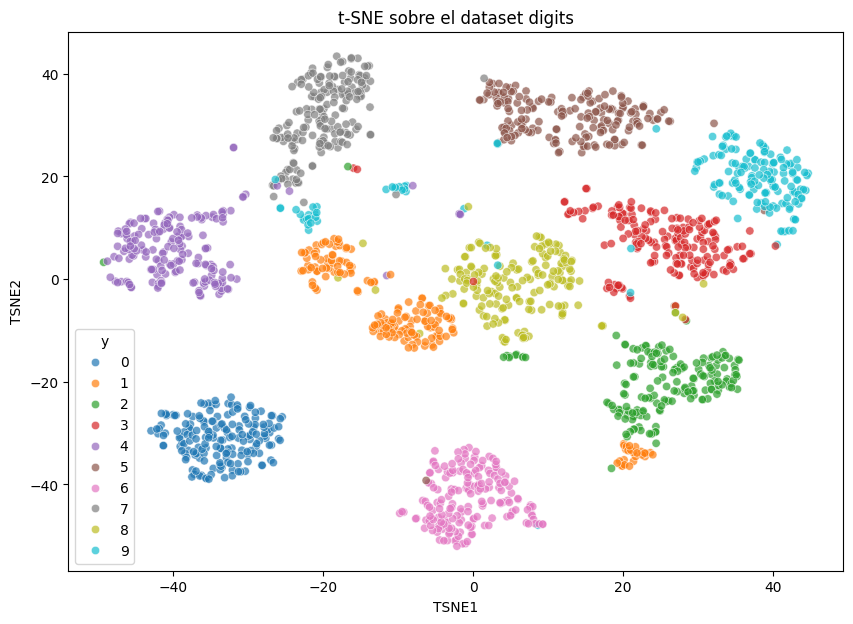

In [68]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    x='TSNE1',
    y='TSNE2',
    hue='y',
    palette='tab10',
    data=df,
    alpha=0.7
)

plt.title("t-SNE sobre el dataset digits")
plt.xlabel("TSNE1")
plt.ylabel("TSNE2")

plt.show()

En el gráfico generado mediante t-SNE se observan agrupaciones más claras de los distintos dígitos en comparación con PCA. Las clases aparecen más separadas, lo que indica que esta técnica captura mejor la estructura del conjunto de datos.

### PCA & t-SNE

In [69]:

# Reducimos la dimensionalidad con PCA a 10 componentes
pca = PCA(n_components=10)

pca_result = pca.fit_transform(features_scaled)

print("Shape after PCA:", pca_result.shape)

# Aplicamos t-SNE sobre el resultado de PCA
tsne = TSNE(n_components=2, random_state=0)

tsne_result = tsne.fit_transform(pca_result)

# Guardar resultados
df['TSNE_PCA1'] = tsne_result[:,0]
df['TSNE_PCA2'] = tsne_result[:,1]

Shape after PCA: (1797, 10)


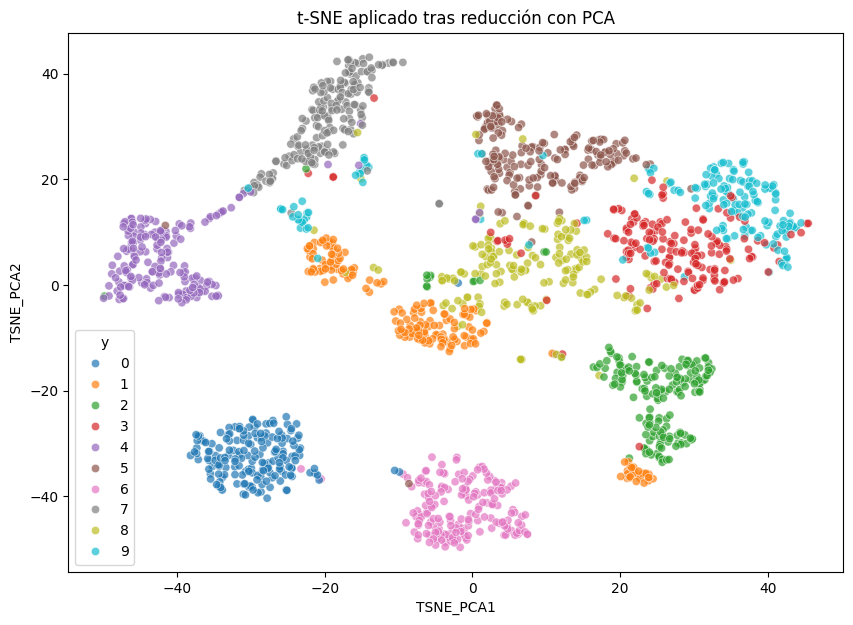

In [71]:
#representacion grafica

plt.figure(figsize=(10,7))

sns.scatterplot(
    x='TSNE_PCA1',
    y='TSNE_PCA2',
    hue='y',
    palette='tab10',
    data=df,
    alpha=0.7
)

plt.title("t-SNE aplicado tras reducción con PCA")
plt.xlabel("TSNE_PCA1")
plt.ylabel("TSNE_PCA2")

plt.show()

La combinación de PCA y t-SNE permite obtener una representación más clara de la estructura del dataset. En primer lugar, PCA reduce la dimensionalidad inicial del conjunto de datos; posteriormente, t-SNE se aplica sobre este espacio reducido para representar los datos en dos dimensiones.